# 4. Robustness, economic value and risk forecasting

Reads the tables produced by `python scripts/make_report.py` (in `reports/tables/`):

- seed robustness of the stochastic models,
- sensitivity to the training window (120 / 240 / 360 months),
- economic value of the forecasts for a market-timing investor,
- forecasting next-month *risk* (|market excess return|) instead of the return.

In [1]:
import os, sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

import pandas as pd
from IPython.display import Image, display

TABLES, FIGURES = Path("reports/tables"), Path("reports/figures")

## 4.1 Seed robustness

Mean, standard deviation and range of OOS R² (%) across random seeds.

In [2]:
pd.read_csv(TABLES / "seed_robustness.csv").round(3)

,Model,r2_mean,r2_std,r2_min,r2_max,cw_p_mean,cov_mean,cer_mean
0,Monte Carlo Linear,-3.548,0.963,-4.830,-2.492,0.594,0.383,-0.463
1,MCLLR (original),-6.052,0.335,-6.598,-5.768,0.633,0.371,-0.255
2,MCLLR ablation: no geometry,-3.423,0.369,-3.917,-2.913,0.582,0.388,-0.879
3,MCLLR (improved),0.246,0.065,0.156,0.335,0.089,0.943,0.997
4,MCLLR (regime state),0.149,0.088,0.056,0.247,0.124,0.944,1.067


## 4.2 Training-window sensitivity

,Model,R² train=120 (%),R² train=240 (%),R² train=360 (%),CW p train=120,CW p train=240,CW p train=360
0,Global OLS,-6.966,-3.282,-3.151,0.655,0.614,0.792
1,Ridge (α = 1),0.019,0.007,0.057,0.367,0.363,0.329
2,LWLR,-8.342,-7.380,-7.488,0.339,0.773,0.854
3,Monte Carlo Linear,-7.091,-3.085,-3.025,0.669,0.524,0.653
4,MCLLR (original),-5.933,-6.577,-6.161,0.284,0.709,0.782
5,MCLLR ablation: no geometry,-7.264,-2.621,-3.678,0.703,0.439,0.824
6,MCLLR ablation: no stochasticity,-12.993,-21.508,-23.674,0.356,0.828,0.813
7,Historical mean (benchmark),0.000,0.000,0.000,0.500,0.500,0.500
8,Ridge (tuned),-1.229,0.248,-0.141,0.532,0.088,0.389
9,MCLLR (improved),-0.507,0.362,-0.127,0.397,0.055,0.404


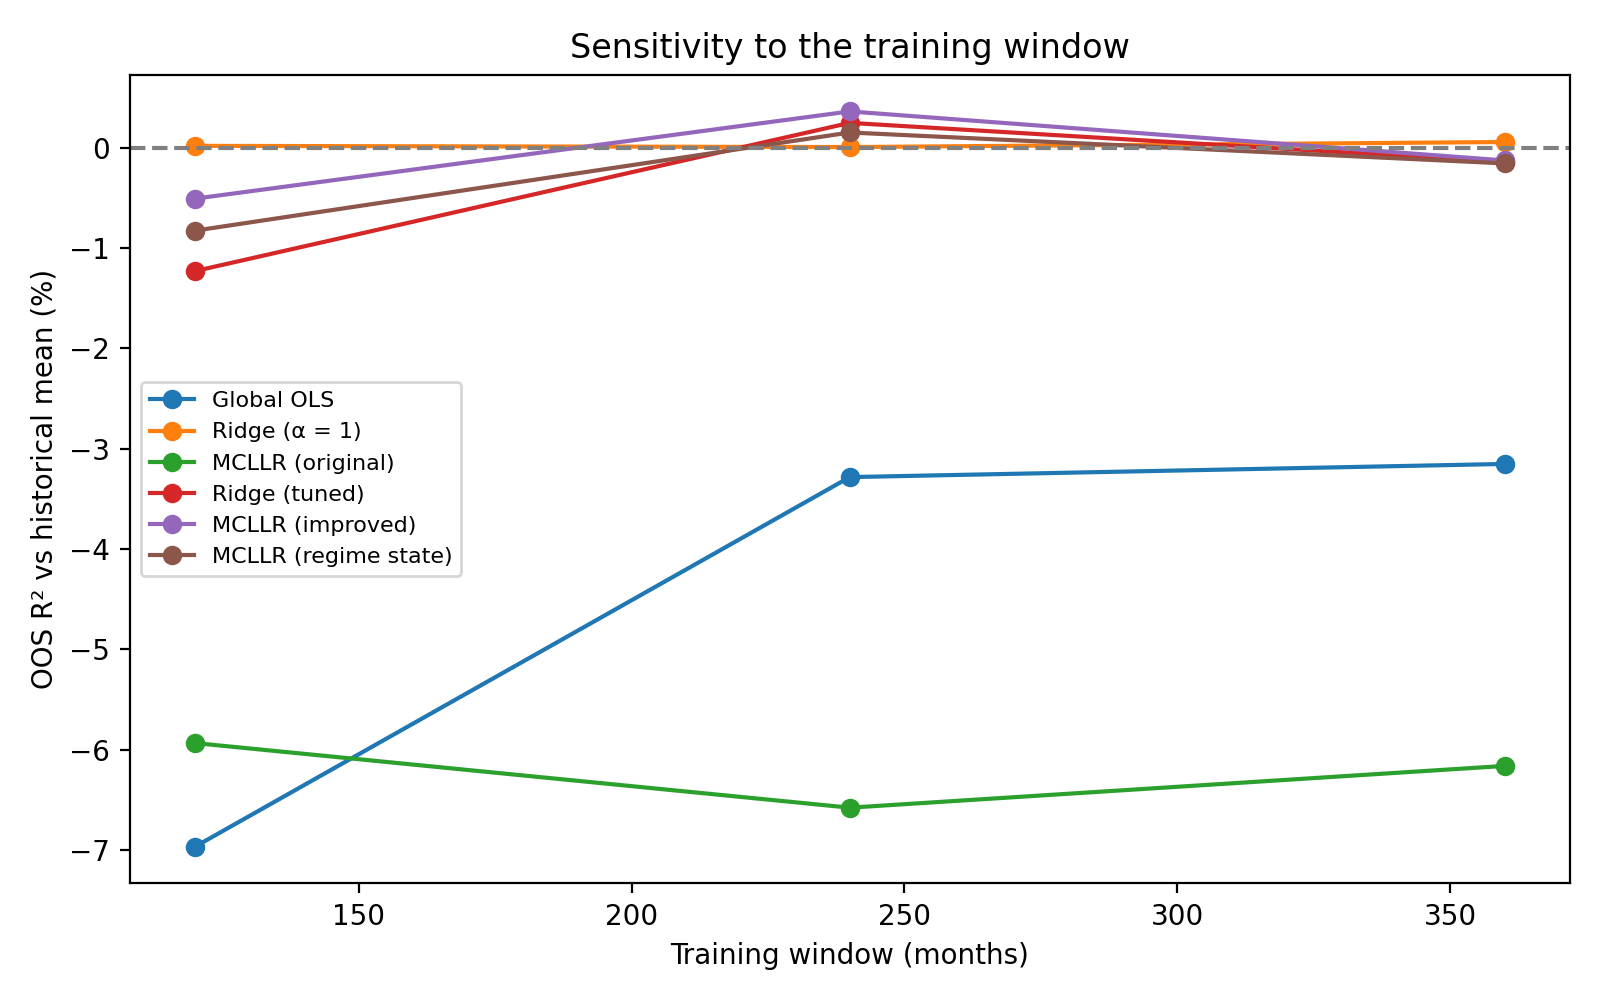

In [3]:
display(pd.read_csv(TABLES / "window_sensitivity.csv").round(3))
display(Image(str(FIGURES / "fig6_window_sensitivity.png")))

## 4.3 Economic value

A mean-variance investor (γ = 3) holds w = forecast / (γ σ²) in the market, clipped to [0, 1.5], with σ² the trailing 60-month variance. CER gain is the annual fee they would pay to use the model instead of the historical mean.

,Model,System,OOS R² (%),CW p,CER gain (%/yr),Sharpe
0,MCLLR (improved),improved,0.361799,0.054788,1.219690,0.535936
1,Ridge (tuned),improved,0.247668,0.088277,0.448471,0.489990
2,MCLLR (regime state),improved,0.151976,0.120536,1.237683,0.537312
3,Ridge (α = 1),standard,0.006685,0.363450,0.212954,0.475371
4,Historical mean (benchmark),improved,0.000000,0.500000,0.000000,0.462721
5,MCLLR ablation: no geometry,standard,-2.620869,0.438554,-0.305793,0.442312
6,Monte Carlo Linear,standard,-3.085494,0.523560,0.000018,0.461964
7,Global OLS,standard,-3.282402,0.613533,-0.563559,0.427140
8,MCLLR (original),standard,-6.576819,0.709126,-0.670799,0.425317
9,LWLR,standard,-7.380453,0.773459,0.141750,0.471416


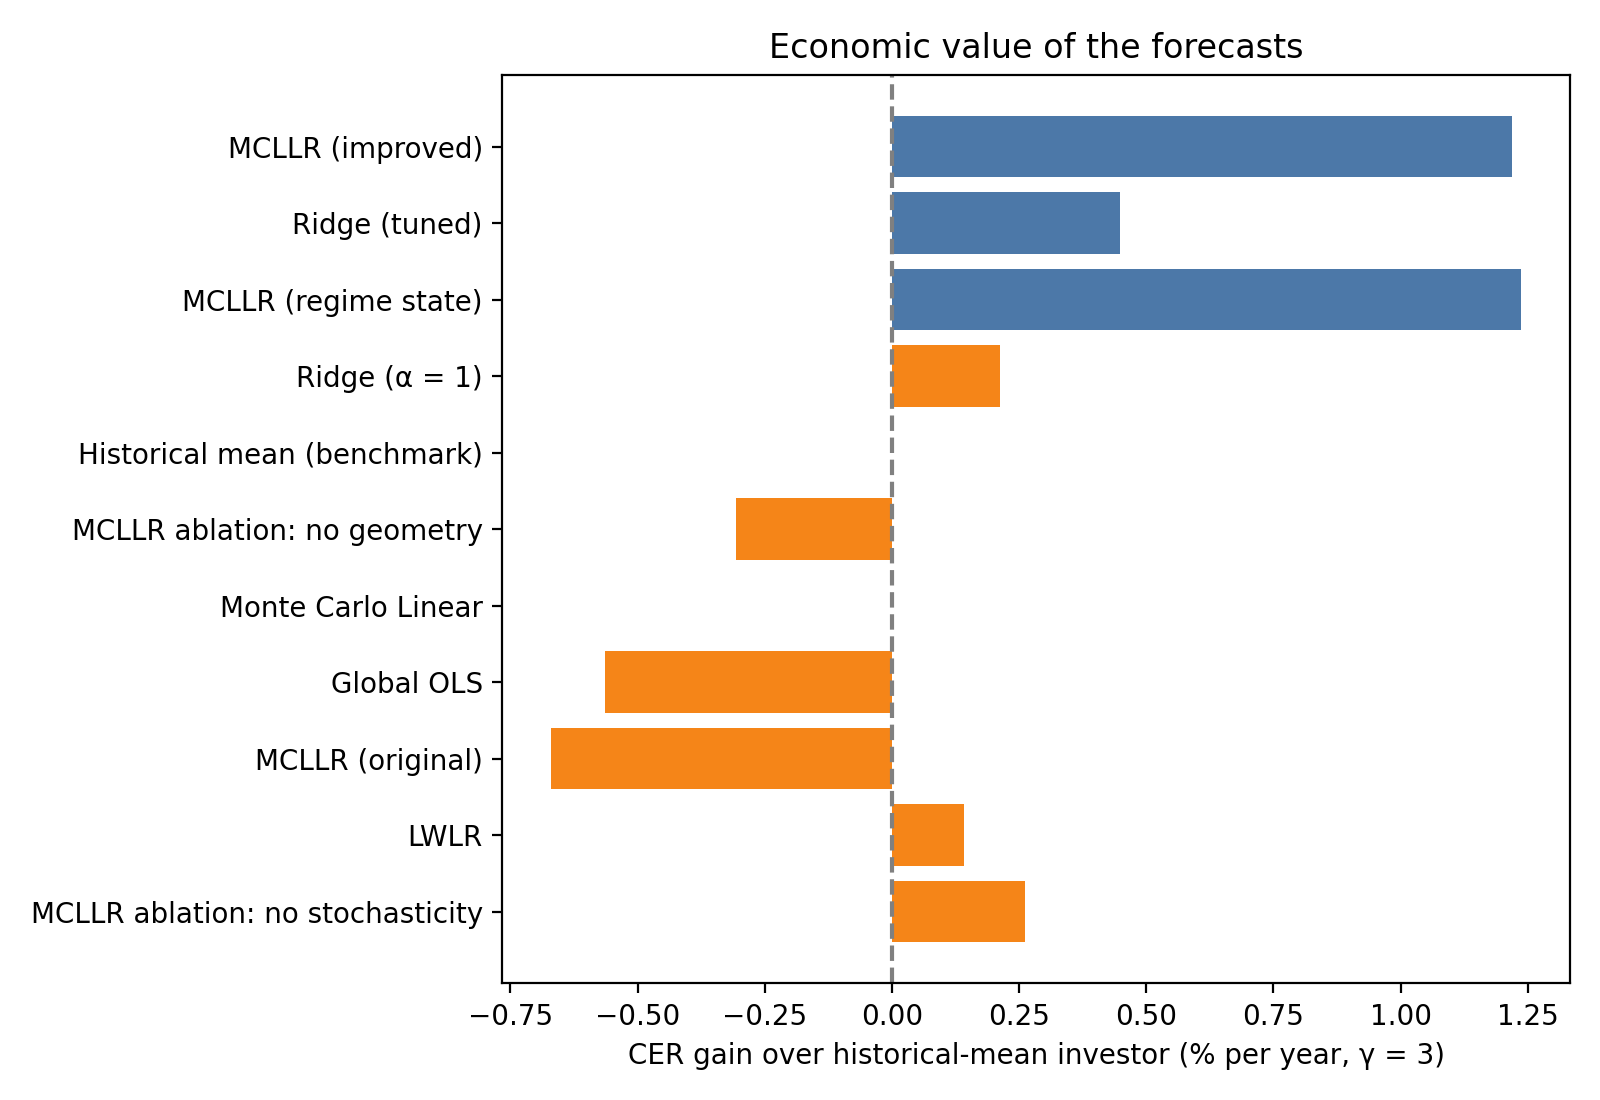

In [4]:
main = pd.read_csv(TABLES / "main_results.csv")
display(main[["Model", "System", "OOS R² (%)", "CW p", "CER gain (%/yr)", "Sharpe"]])
display(Image(str(FIGURES / "fig5_economic_value.png")))

## 4.4 Risk forecasting: |next-month return|

Volatility clusters, so this target should reward locality. Linear global models cannot use the *size* of this month's return because they are linear in the signed factors; local models can.

,Model,RMSE,MAE,OOS R² (%),DM p,CW p,95% cov.,Int. score
0,historical_mean,0.0289,0.0218,0.0000,1.0000,0.5000,0.9504,0.1632
1,ridge,0.0285,0.0216,2.6556,0.0847,0.0002,0.9603,0.1577
2,mcllr_improved,0.0284,0.0213,3.4488,0.0158,0.0001,0.9464,0.1605
3,mcllr_regime,0.0282,0.0212,4.6504,0.0008,0.0000,0.9504,0.1575


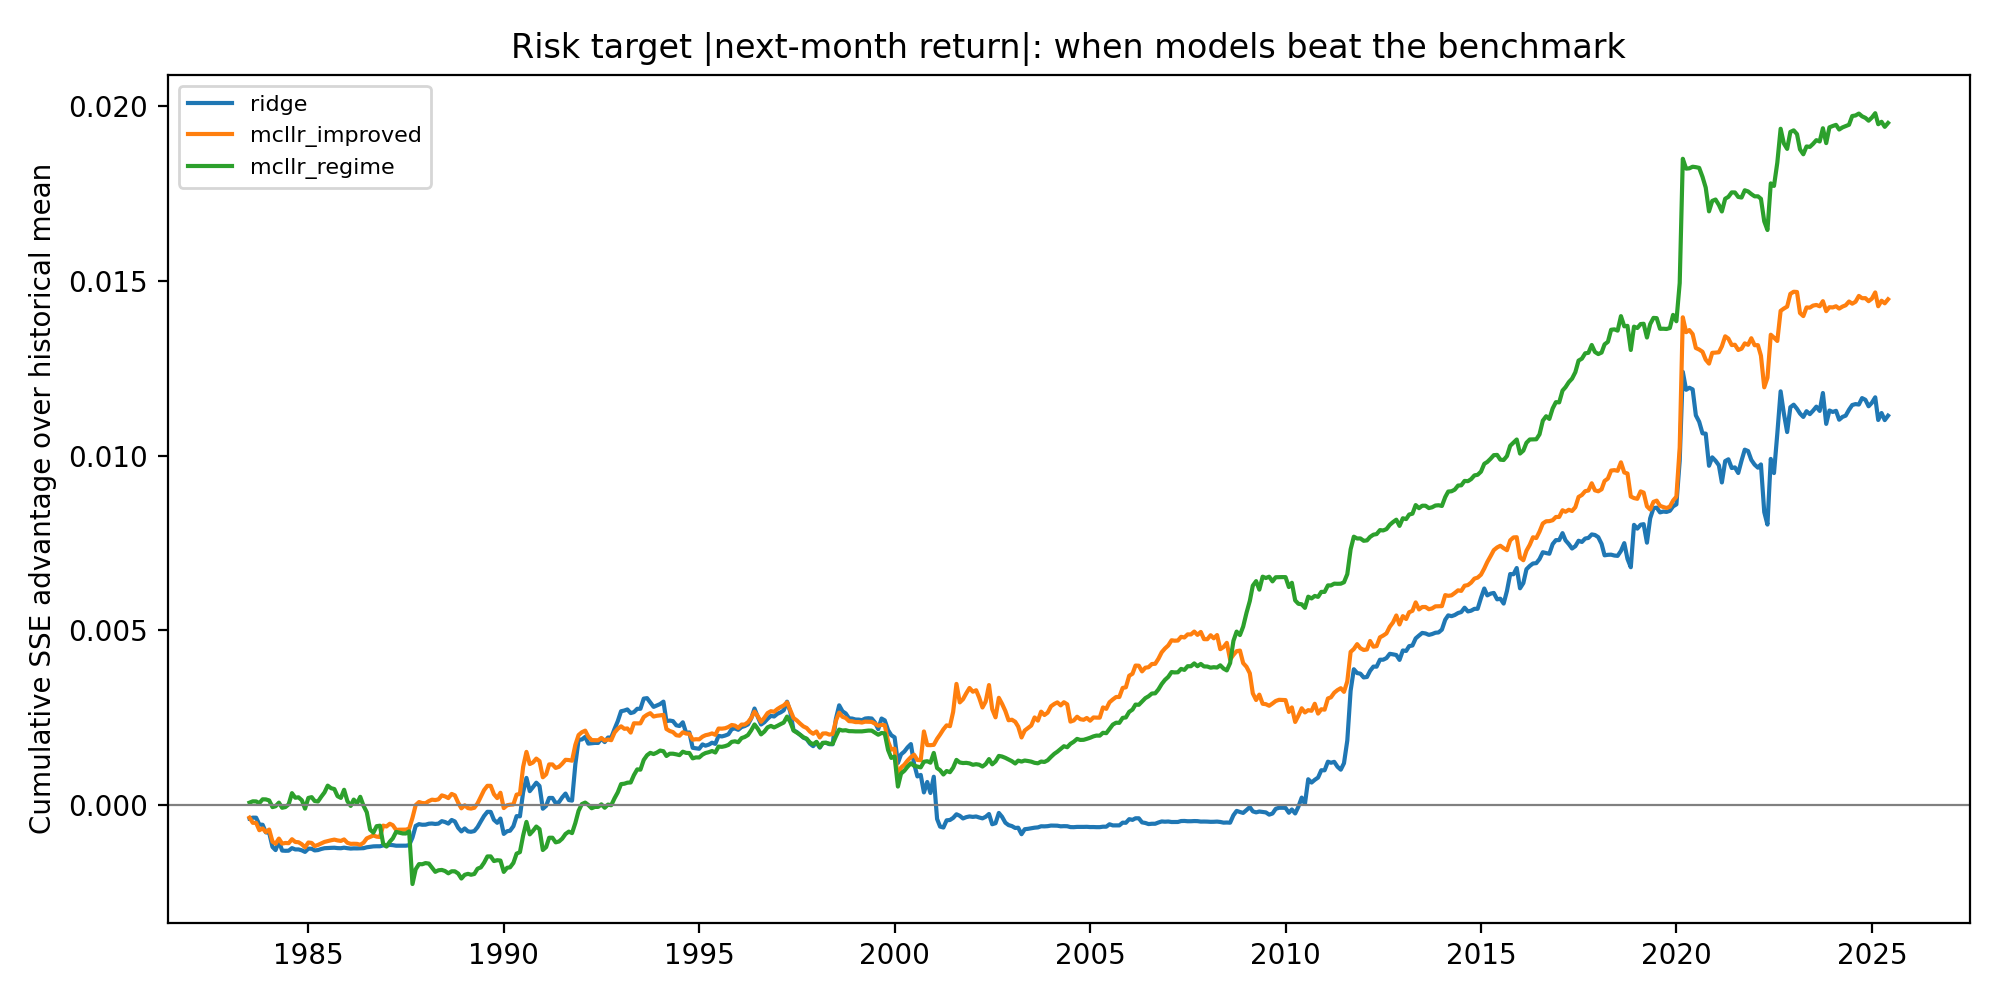

In [5]:
display(pd.read_csv(TABLES / "risk_target.csv").round(4))
display(Image(str(FIGURES / "fig7_risk_target.png")))